# Prediction of diabetes_status value with Gradient Boosting

## Load the saved splits

Gradient boosting does not need scaling, and `HistGradientBoostingClassifier` handles missing values natively, so this notebook uses the **unscaled** splits with the NaNs left in. The train/test rows are the same ones logistic regression used, which keeps the comparison fair.

In [1]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import loguniform
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, cross_val_predict
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    roc_auc_score, average_precision_score, precision_score, recall_score, f1_score,
    accuracy_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve, precision_recall_curve
)

RANDOM_STATE = 42
os.makedirs("figures", exist_ok=True)

X_train = pd.read_parquet("data/X_train.parquet")
X_test  = pd.read_parquet("data/X_test.parquet")
y_train = pd.read_parquet("data/y_train.parquet")["diabetes_status"]
y_test  = pd.read_parquet("data/y_test.parquet")["diabetes_status"]

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Missing values kept in X (train, test):", int(X_train.isna().sum().sum()), int(X_test.isna().sum().sum()))
print("Prevalence  train: %.4f | test: %.4f" % (y_train.mean(), y_test.mean()))

Train: (78384, 12) | Test: (19596, 12)
Missing values kept in X (train, test): 12353 3155
Prevalence  train: 0.2797 | test: 0.2797


## Baseline model

`HistGradientBoostingClassifier` with defaults as a reference point. This is scikit-learn's histogram-based boosting, the same idea as LightGBM, and it is much faster than the older `GradientBoostingClassifier` on 78k rows. Metrics are computed on the held-out test set.

In [2]:
def evaluate(name, y_true, prob, threshold=0.5):
    pred = (prob >= threshold).astype(int)
    return {
        "model": name,
        "threshold": round(threshold, 3),
        "roc_auc": roc_auc_score(y_true, prob),
        "pr_auc": average_precision_score(y_true, prob),
        "accuracy": accuracy_score(y_true, pred),
        "precision": precision_score(y_true, pred, zero_division=0),
        "recall": recall_score(y_true, pred),
        "f1": f1_score(y_true, pred),
    }

baseline = HistGradientBoostingClassifier(random_state=RANDOM_STATE)
baseline.fit(X_train, y_train)
base_prob = baseline.predict_proba(X_test)[:, 1]

pd.DataFrame([evaluate("Baseline (defaults)", y_test, base_prob)]).round(4)

,model,threshold,roc_auc,pr_auc,accuracy,precision,recall,f1
0,Baseline (defaults),0.5,0.7774,0.6629,0.7981,0.7271,0.4454,0.5524


## Hyperparameter tuning

Randomized search with 5-fold stratified cross-validation on the **training set only**, scored by ROC-AUC. The number of trees is not searched directly: early stopping (a held-out 10% of each training fold, patience of 20 rounds) picks it. The main controls on overfitting are the learning rate, tree size, `min_samples_leaf` and L2 regularization. The test set is not used here.

In [3]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

param_dist = {
    "learning_rate": loguniform(0.01, 0.2),
    "max_depth": [2, 3, 4, 5, 6, None],
    "max_leaf_nodes": [8, 15, 31],
    "min_samples_leaf": [20, 50, 100, 200, 400],
    "l2_regularization": [0, 0.1, 1, 10],
}
search = RandomizedSearchCV(
    HistGradientBoostingClassifier(
        max_iter=1000, early_stopping=True, validation_fraction=0.1,
        n_iter_no_change=20, random_state=RANDOM_STATE,
    ),
    param_dist, n_iter=25, scoring="roc_auc", cv=cv, n_jobs=1,
    random_state=RANDOM_STATE, return_train_score=True,
)
search.fit(X_train, y_train)

print("Best params:", {k: (round(float(v), 4) if isinstance(v, (float, np.floating)) else v) for k, v in search.best_params_.items()})
print("Best CV ROC-AUC: %.4f" % search.best_score_)
print("Trees chosen by early stopping (final refit):", search.best_estimator_.n_iter_)

cv_results = (
    pd.DataFrame(search.cv_results_)[[
        "param_learning_rate", "param_max_depth", "param_max_leaf_nodes", "param_min_samples_leaf",
        "param_l2_regularization", "mean_train_score", "mean_test_score", "std_test_score",
    ]]
    .sort_values("mean_test_score", ascending=False)
    .round(4)
)
cv_results.head(8)

Best params: {'l2_regularization': 0.1, 'learning_rate': 0.0327, 'max_depth': 5, 'max_leaf_nodes': 15, 'min_samples_leaf': 200}
Best CV ROC-AUC: 0.7788
Trees chosen by early stopping (final refit): 335


,param_learning_rate,param_max_depth,param_max_leaf_nodes,param_min_samples_leaf,param_l2_regularization,mean_train_score,mean_test_score,std_test_score
14,0.0327,5,15,200,0.1,0.7943,0.7788,0.0036
6,0.0240,None,15,100,10.0,0.7955,0.7788,0.0037
12,0.0173,5,15,50,10.0,0.7940,0.7786,0.0034
24,0.0315,None,31,20,0.0,0.8075,0.7785,0.0038
10,0.0105,3,31,200,0.0,0.7870,0.7784,0.0036
19,0.0102,4,31,20,10.0,0.7925,0.7784,0.0034
13,0.0174,3,15,200,10.0,0.7886,0.7784,0.0036
5,0.0107,4,31,50,10.0,0.7918,0.7784,0.0033


Compare `mean_train_score` with `mean_test_score`. A large gap would mean the trees are memorizing the training data. The best settings should show a small gap.

## Decision threshold

Same approach as logistic regression: pick the F1-maximizing threshold from **out-of-fold training predictions**, so the test set stays untouched. `class_weight="balanced"` is compared as the alternative.

In [4]:
best = search.best_estimator_

balanced = HistGradientBoostingClassifier(
    **{**search.best_estimator_.get_params(), "class_weight": "balanced"}
).fit(X_train, y_train)

oof_prob = cross_val_predict(best, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
prec, rec, thr = precision_recall_curve(y_train, oof_prob)
f1s = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
best_thr = thr[np.argmax(f1s)]
print("F1-optimal threshold (from training OOF predictions): %.3f" % best_thr)

tuned_prob = best.predict_proba(X_test)[:, 1]
balanced_prob = balanced.predict_proba(X_test)[:, 1]

results = pd.DataFrame([
    evaluate("Baseline (defaults), t=0.5", y_test, base_prob),
    evaluate("Tuned, t=0.5", y_test, tuned_prob),
    evaluate("Tuned + balanced weights, t=0.5", y_test, balanced_prob),
    evaluate("Tuned, F1-optimal threshold", y_test, tuned_prob, threshold=best_thr),
]).round(4)
results

F1-optimal threshold (from training OOF predictions): 0.297


,model,threshold,roc_auc,pr_auc,accuracy,precision,recall,f1
0,"Baseline (defaults), t=0.5",0.500,0.7774,0.6629,0.7981,0.7271,0.4454,0.5524
1,"Tuned, t=0.5",0.500,0.7780,0.6655,0.7990,0.7337,0.4419,0.5516
2,"Tuned + balanced weights, t=0.5",0.500,0.7776,0.6649,0.7593,0.5617,0.6357,0.5964
3,"Tuned, F1-optimal threshold",0.297,0.7780,0.6655,0.7672,0.5781,0.6205,0.5986


## Test-set evaluation plots

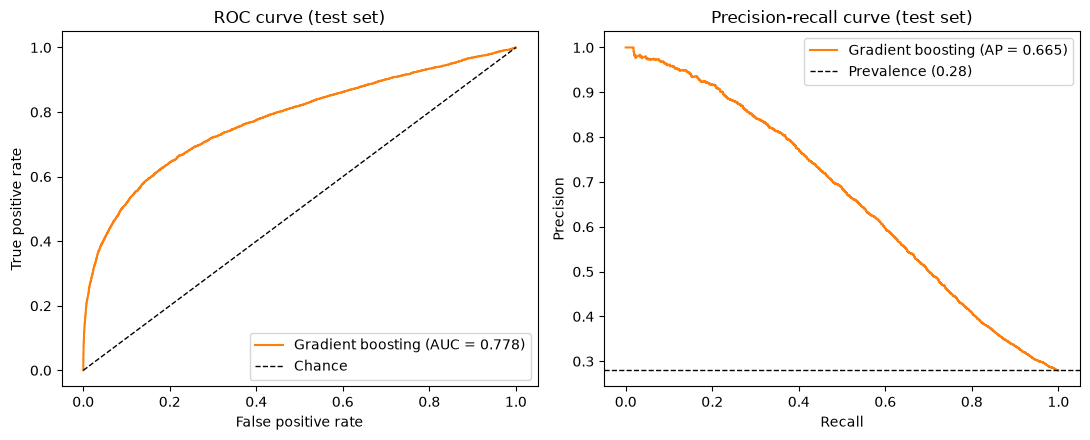

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

fpr, tpr, _ = roc_curve(y_test, tuned_prob)
axes[0].plot(fpr, tpr, color="tab:orange", label="Gradient boosting (AUC = %.3f)" % roc_auc_score(y_test, tuned_prob))
axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="Chance")
axes[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curve (test set)")
axes[0].legend(loc="lower right")

p, r, _ = precision_recall_curve(y_test, tuned_prob)
axes[1].plot(r, p, color="tab:orange", label="Gradient boosting (AP = %.3f)" % average_precision_score(y_test, tuned_prob))
axes[1].axhline(y_test.mean(), color="k", ls="--", lw=1, label="Prevalence (%.2f)" % y_test.mean())
axes[1].set(xlabel="Recall", ylabel="Precision", title="Precision-recall curve (test set)")
axes[1].legend(loc="upper right")

plt.tight_layout()
plt.savefig("figures/gb_roc_pr.png", dpi=200, bbox_inches="tight")
plt.show()

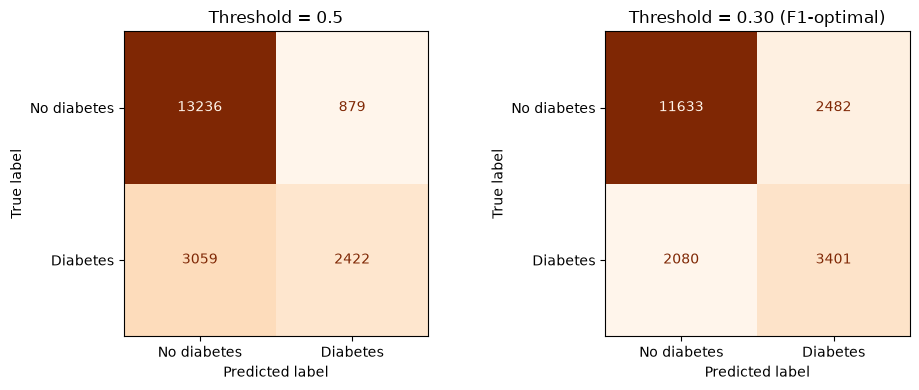

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, thr_, title in zip(axes, [0.5, best_thr], ["Threshold = 0.5", "Threshold = %.2f (F1-optimal)" % best_thr]):
    cm = confusion_matrix(y_test, (tuned_prob >= thr_).astype(int))
    ConfusionMatrixDisplay(cm, display_labels=["No diabetes", "Diabetes"]).plot(ax=ax, colorbar=False, values_format="d", cmap="Oranges")
    ax.set_title(title)
plt.tight_layout()
plt.savefig("figures/gb_confusion_matrices.png", dpi=200, bbox_inches="tight")
plt.show()

## Uncertainty in the test AUC

Bootstrap (1,000 resamples of the test set) for a 95% confidence interval on ROC-AUC.

In [7]:
rng = np.random.default_rng(RANDOM_STATE)
y_arr = y_test.to_numpy()
n = len(y_arr)
boot_idx = [rng.integers(0, n, n) for _ in range(1000)]
boot_auc = [roc_auc_score(y_arr[i], tuned_prob[i]) for i in boot_idx]
ci = np.percentile(boot_auc, [2.5, 97.5])
print("Test ROC-AUC: %.4f (95%% bootstrap CI: %.4f to %.4f)" % (roc_auc_score(y_test, tuned_prob), *ci))

Test ROC-AUC: 0.7780 (95% bootstrap CI: 0.7695 to 0.7866)


## Interpretation: which features matter?

**Permutation importance** on the test set: shuffle one feature at a time and measure how much ROC-AUC drops. It is model-agnostic, so the same method could be applied to logistic regression. Unlike the built-in impurity importances, it is not biased toward features with many distinct values.

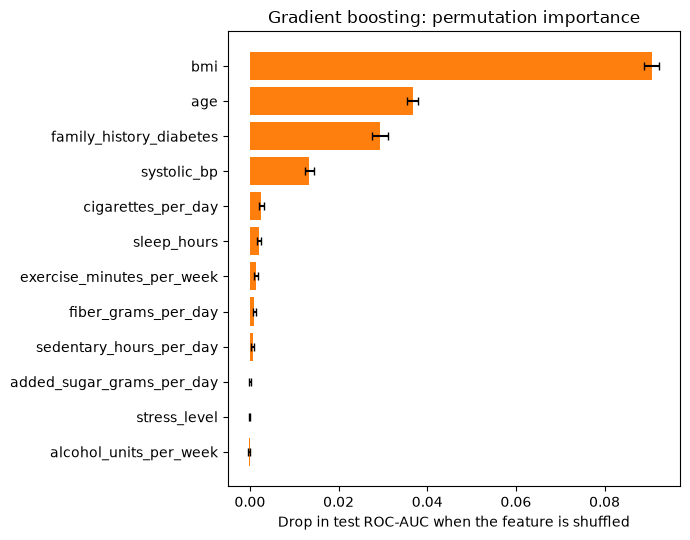

,importance_mean,importance_std
bmi,0.0906,0.0018
age,0.0367,0.0012
family_history_diabetes,0.0294,0.0017
systolic_bp,0.0134,0.0010
cigarettes_per_day,0.0026,0.0006
sleep_hours,0.0021,0.0004
exercise_minutes_per_week,0.0014,0.0004
fiber_grams_per_day,0.0010,0.0004
sedentary_hours_per_day,0.0006,0.0003
added_sugar_grams_per_day,-0.0000,0.0002


In [8]:
perm = permutation_importance(
    best, X_test, y_test, scoring="roc_auc", n_repeats=10, random_state=RANDOM_STATE, n_jobs=1
)
imp = (
    pd.DataFrame({"importance_mean": perm.importances_mean, "importance_std": perm.importances_std}, index=X_test.columns)
    .sort_values("importance_mean", ascending=False)
)

plot_df = imp.sort_values("importance_mean")
fig, ax = plt.subplots(figsize=(7, 5.5))
ax.barh(plot_df.index, plot_df["importance_mean"], xerr=plot_df["importance_std"], color="tab:orange", capsize=3)
ax.set_xlabel("Drop in test ROC-AUC when the feature is shuffled")
ax.set_title("Gradient boosting: permutation importance")
plt.tight_layout()
plt.savefig("figures/gb_permutation_importance.png", dpi=200, bbox_inches="tight")
plt.show()

imp.round(4)

**Partial dependence** for the four most important features shows the shape of each relationship. Logistic regression forces these to be straight lines on the log-odds scale. If gradient boosting finds clear curves, bends or plateaus, that is the nonlinearity it can exploit.

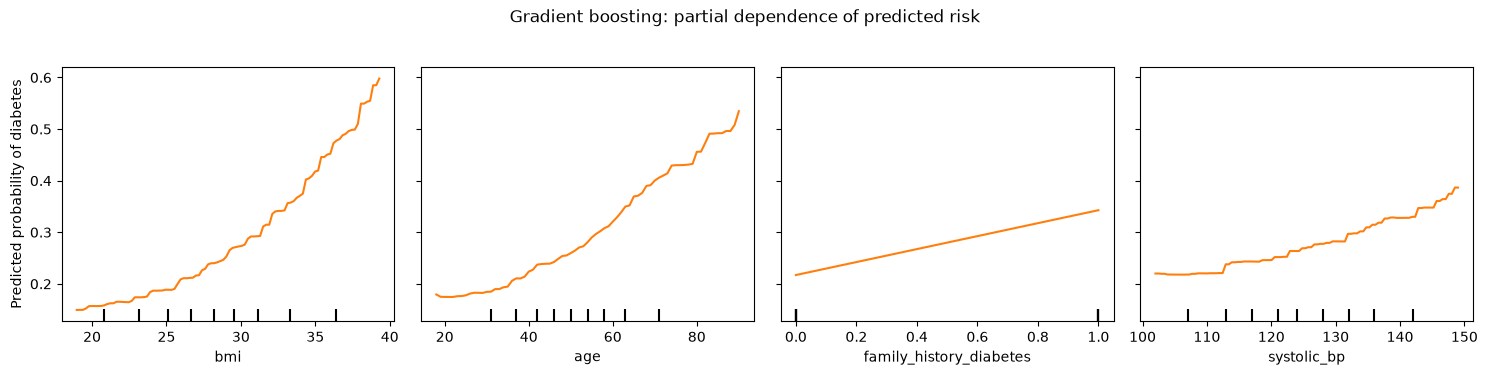

In [9]:
top4 = list(imp.index[:4])
sample = X_train.sample(5000, random_state=RANDOM_STATE).astype(float)  # partial dependence needs float columns

fig, axes = plt.subplots(1, 4, figsize=(15, 3.6), sharey=True)
PartialDependenceDisplay.from_estimator(
    best, sample, top4, kind="average", ax=axes, method="brute", response_method="predict_proba",
    line_kw={"color": "tab:orange"}, n_jobs=1
)
axes[0].set_ylabel("Predicted probability of diabetes")
for a in axes[1:]:
    a.set_ylabel("")
fig.suptitle("Gradient boosting: partial dependence of predicted risk", y=1.03)
plt.tight_layout()
plt.savefig("figures/gb_partial_dependence.png", dpi=200, bbox_inches="tight")
plt.show()

## Comparison with logistic regression

Loads the logistic regression test-set probabilities saved by `logistic_regression.ipynb` (same test rows) and compares the two on discrimination, calibration and the F1-optimal operating point. The AUC difference gets a **paired** bootstrap: both models are scored on the same resampled rows, so the interval reflects the difference itself rather than each model's separate uncertainty.

In [10]:
lr = pd.read_parquet("data/lr_test_probs.parquet")
assert (lr["y_true"].to_numpy() == y_test.to_numpy()).all() and (lr.index == y_test.index).all(), "Test rows differ between models"
lr_prob = lr["prob"].to_numpy()

# Metrics table (each model at its own F1-optimal training threshold, plus the 0.5 default)
lr_metrics = pd.read_csv("data/lr_metrics.csv")
lr_thr = float(lr_metrics.loc[lr_metrics["model"].str.contains("F1-optimal"), "threshold"].iloc[0])
comparison = pd.DataFrame([
    evaluate("Logistic regression, t=0.5", y_test, lr_prob),
    evaluate("Gradient boosting, t=0.5", y_test, tuned_prob),
    evaluate("Logistic regression, F1-opt", y_test, lr_prob, threshold=lr_thr),
    evaluate("Gradient boosting, F1-opt", y_test, tuned_prob, threshold=best_thr),
]).round(4)
display(comparison)

# Paired bootstrap of the AUC difference (GB minus LR)
diffs = np.array([
    roc_auc_score(y_arr[i], tuned_prob[i]) - roc_auc_score(y_arr[i], lr_prob[i]) for i in boot_idx
])
d_ci = np.percentile(diffs, [2.5, 97.5])
print("AUC difference (GB - LR): %.4f (95%% paired bootstrap CI: %.4f to %.4f)" % (diffs.mean(), *d_ci))
print("Interval excludes 0:", bool(d_ci[0] > 0 or d_ci[1] < 0))

,model,threshold,roc_auc,pr_auc,accuracy,precision,recall,f1
0,"Logistic regression, t=0.5",0.500,0.7806,0.6673,0.7999,0.7327,0.4481,0.5561
1,"Gradient boosting, t=0.5",0.500,0.7780,0.6655,0.7990,0.7337,0.4419,0.5516
2,"Logistic regression, F1-opt",0.387,0.7806,0.6673,0.7781,0.6051,0.5946,0.5998
3,"Gradient boosting, F1-opt",0.297,0.7780,0.6655,0.7672,0.5781,0.6205,0.5986


AUC difference (GB - LR): -0.0026 (95% paired bootstrap CI: -0.0044 to -0.0008)
Interval excludes 0: True


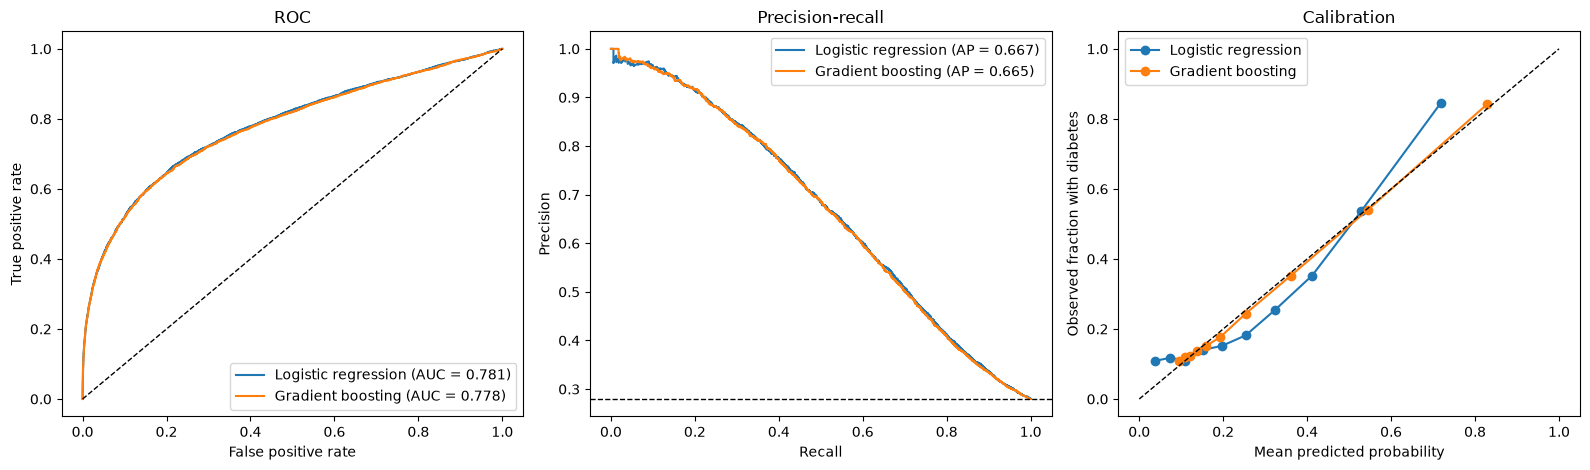

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

for prob, name, color in [(lr_prob, "Logistic regression", "tab:blue"), (tuned_prob, "Gradient boosting", "tab:orange")]:
    fpr, tpr, _ = roc_curve(y_test, prob)
    axes[0].plot(fpr, tpr, color=color, label="%s (AUC = %.3f)" % (name, roc_auc_score(y_test, prob)))
    p, r, _ = precision_recall_curve(y_test, prob)
    axes[1].plot(r, p, color=color, label="%s (AP = %.3f)" % (name, average_precision_score(y_test, prob)))
    fp, mp = calibration_curve(y_test, prob, n_bins=10, strategy="quantile")
    axes[2].plot(mp, fp, "o-", color=color, label=name)

axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC")
axes[0].legend(loc="lower right")
axes[1].axhline(y_test.mean(), color="k", ls="--", lw=1)
axes[1].set(xlabel="Recall", ylabel="Precision", title="Precision-recall")
axes[1].legend(loc="upper right")
axes[2].plot([0, 1], [0, 1], "k--", lw=1)
axes[2].set(xlabel="Mean predicted probability", ylabel="Observed fraction with diabetes", title="Calibration")
axes[2].legend(loc="upper left")

plt.tight_layout()
plt.savefig("figures/comparison_roc_pr_calibration.png", dpi=200, bbox_inches="tight")
plt.show()

## Save outputs

In [12]:
pd.DataFrame({"y_true": y_test.to_numpy(), "prob": tuned_prob}, index=y_test.index).to_parquet("data/gb_test_probs.parquet")
results.to_csv("data/gb_metrics.csv", index=False)
comparison.to_csv("data/model_comparison_metrics.csv", index=False)
imp.to_csv("data/gb_permutation_importance.csv")
joblib.dump(best, "data/gb_best_model.joblib")
print(sorted(f for f in os.listdir("data") if f.startswith(("gb_", "model_"))))

['gb_best_model.joblib', 'gb_metrics.csv', 'gb_permutation_importance.csv', 'gb_test_probs.parquet', 'model_comparison_metrics.csv']
